# Data Availability Statement Categories — Deep-Dive Analysis (2011–2025)

> **Research question:** Beyond *whether* an article shares data (covered in
> `01_corpus_overview.ipynb`), *how* does it share it — and how has the mix, quality, and
> trajectory of DAS categories evolved since the FAIR principles were published in March 2016?

Stage 4 of the pipeline (`categorise_das.py`) assigns every article one of **nine primary DAS
categories**, ordered here roughly by FAIR compliance:

| Category | Meaning |
|----------|---------|
| `repository_named` | DAS names a specific data repository (best practice) |
| `accession_provided` | DAS contains a database accession number |
| `no_das_but_accession` | No DAS section, but an inline accession number exists elsewhere |
| `open_unspecified` | DAS states data is open/available but without a repository or accession |
| `supplementary_only` | Data is only in the article's own supplementary files |
| `no_das_but_supp` | No DAS section, but supplementary files exist |
| `available_on_request` | DAS states data is available on request (restrictive) |
| `restricted` | DAS explicitly restricts access (governance/privacy reasons) |
| `no_statement` | No data-sharing signal at all |

This notebook treats the **category itself** as the object of study: its internal structure
(text richness, secondary signals), its link to actual repository quality, which journals and
publishers lead or lag, and how individual journals' category mix has shifted pre- to post-FAIR.
Cross-cuts by discipline, open-access status, and funder are covered in
`11_geographical.ipynb` and `08_mandate_compliance.ipynb` and are not repeated here.

| § | Content |
|---|---------|
| 0 | Setup, master frame |
| 1 | Category prevalence & composition over time |
| 2 | DAS text richness by category |
| 3 | Secondary signal rates by category |
| 4 | Data-sharing score by category |
| 5 | Category × repository infrastructure tier |
| 6 | Restrictive-sharing deep-dive |
| 7 | Publisher league table |
| 8 | Journal improvement trajectories (pre- vs post-FAIR) |
| 9 | Statistical summary: chi-squared tests per category |
| 10 | Key findings & exports |

---

In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


## 0 · Setup

In [2]:
import sqlite3, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", font_scale=1.15)
PALETTE   = sns.color_palette("tab10")
FAIR_YEAR = 2016
FIG_W, FIG_H = 13, 5

DB_PATH = Path("../data/processed/pmc_fair.db")
assert DB_PATH.exists(), f"Database not found: {DB_PATH}"
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def q(sql, params=()):
    """Run a query and return a DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
required = {"article","data_availability","das_category","repo_classification","da_link"}
missing  = required - tables
if missing:
    print(f"⚠️  Missing tables (run corresponding pipeline stages): {missing}")
else:
    print("✅ All required tables present")

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"

# ── Category order, labels, colours (shared convention across notebooks) ───
CAT_ORDER = [
    "repository_named", "accession_provided", "no_das_but_accession",
    "open_unspecified", "supplementary_only", "no_das_but_supp",
    "available_on_request", "restricted", "no_statement",
]
CAT_LABELS = {
    "repository_named":      "Named repository",
    "accession_provided":    "Accession # in DAS",
    "no_das_but_accession":  "Accession (no DAS)",
    "open_unspecified":      "Open (unspecified)",
    "supplementary_only":    "Supplementary only",
    "no_das_but_supp":       "Supp. (no DAS)",
    "available_on_request":  "Available on request",
    "restricted":            "Restricted",
    "no_statement":          "No statement",
}
CAT_COLOURS = {
    "repository_named":      "#2ca02c",
    "accession_provided":    "#98df8a",
    "no_das_but_accession":  "#b5cf6b",
    "open_unspecified":      "#aec7e8",
    "supplementary_only":    "#ffbb78",
    "no_das_but_supp":       "#ffd8b1",
    "available_on_request":  "#d62728",
    "restricted":            "#ff9896",
    "no_statement":          "#c7c7c7",
}
RESTRICTIVE = ["available_on_request", "restricted", "no_statement"]

# ── Master frame ────────────────────────────────────────────────────────────
df = q("""
    SELECT dc.article_id, a.year AS year, a.journal_id,
           dc.primary_category   AS category,
           dc.data_sharing_score,
           dc.mentions_license, dc.mentions_doi, dc.mentions_github,
           dc.has_url, dc.has_accession,
           dc.word_count, dc.sentence_count
    FROM das_category dc
    JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")
df["is_restrictive"] = df["category"].isin(RESTRICTIVE)

jrnl = q("SELECT journal_id, title AS jrnl_title, publisher FROM journal")
df = df.merge(jrnl, on="journal_id", how="left")

print(f"Master frame: {len(df):,} articles")
print(df["category"].value_counts().reindex(CAT_ORDER).to_string())

✅ All required tables present


Master frame: 6,874,176 articles


category
repository_named         459873
accession_provided        17602
no_das_but_accession    2756128
open_unspecified        1054657
supplementary_only       441421
no_das_but_supp          135925
available_on_request     824949
restricted               212541
no_statement             971080


---
## 1 · Category Prevalence & Composition Over Time

Full year-by-year breakdown of all nine categories (§2 of `01_corpus_overview.ipynb` shows
this only for two headline categories) plus the **Shannon diversity** of the category mix each
year — does the category mix concentrate into fewer dominant patterns over time, or diversify?

Category counts per year:
category  repository_named  accession_provided  no_das_but_accession  open_unspecified  supplementary_only  no_das_but_supp  available_on_request  restricted  no_statement
year                                                                                                                                                                       
2011                   132                  24                 81723              1689                  14             1776                    77          33         24879
2012                   357                  43                109685              2502                  67             2369                   138          41         33065
2013                   780                  33                140653              1302                 145             3643                   174          41         40441
2014                  3050                 203                154873             10564                 445        

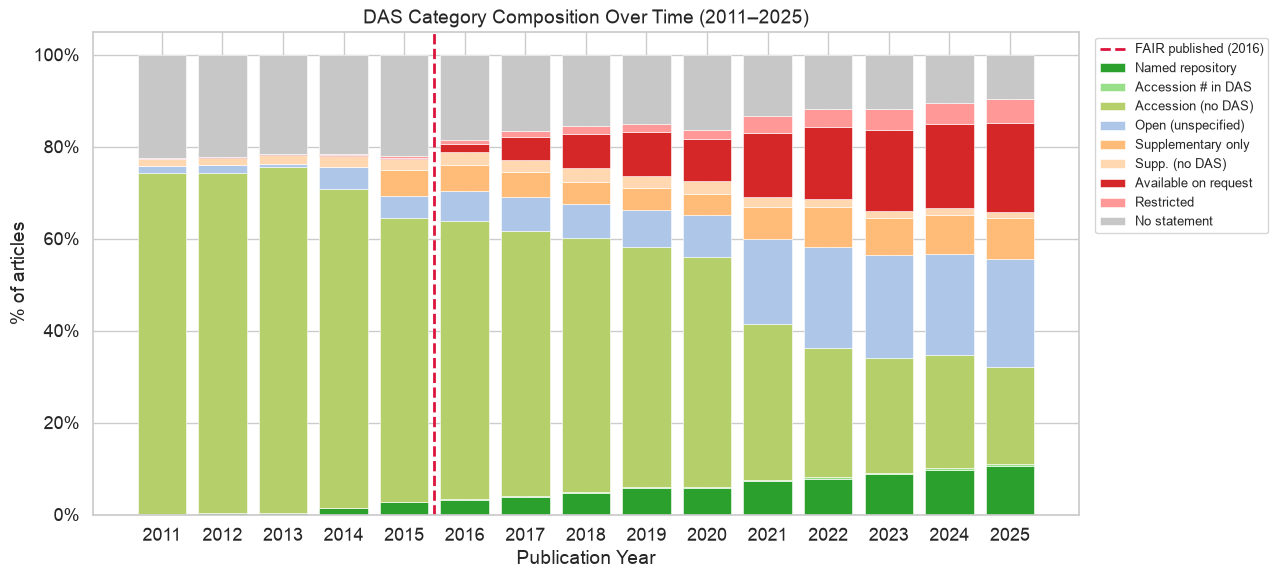

In [3]:
# ── 1.1 Category counts & composition per year ──────────────────────────────
pivot = df.pivot_table(index="year", columns="category", values="article_id",
                        aggfunc="count", fill_value=0)
pivot = pivot.reindex(columns=[c for c in CAT_ORDER if c in pivot.columns])
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

print("Category counts per year:")
print(pivot.to_string())

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H + 1))
bottom = np.zeros(len(pivot_pct))
for cat in pivot_pct.columns:
    vals = pivot_pct[cat].values
    ax.bar(pivot_pct.index, vals, bottom=bottom, color=CAT_COLOURS.get(cat, "#888"),
           label=CAT_LABELS.get(cat, cat), edgecolor="white", linewidth=0.4)
    bottom += vals
ax.axvline(FAIR_YEAR - 0.5, color="crimson", lw=2, ls="--", label="FAIR published (2016)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Publication Year"); ax.set_ylabel("% of articles")
ax.set_title("DAS Category Composition Over Time (2011–2025)")
ax.set_xticks(pivot_pct.index)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9, frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_01_composition.png", **SAVEFIG_KWARGS)
plt.show()

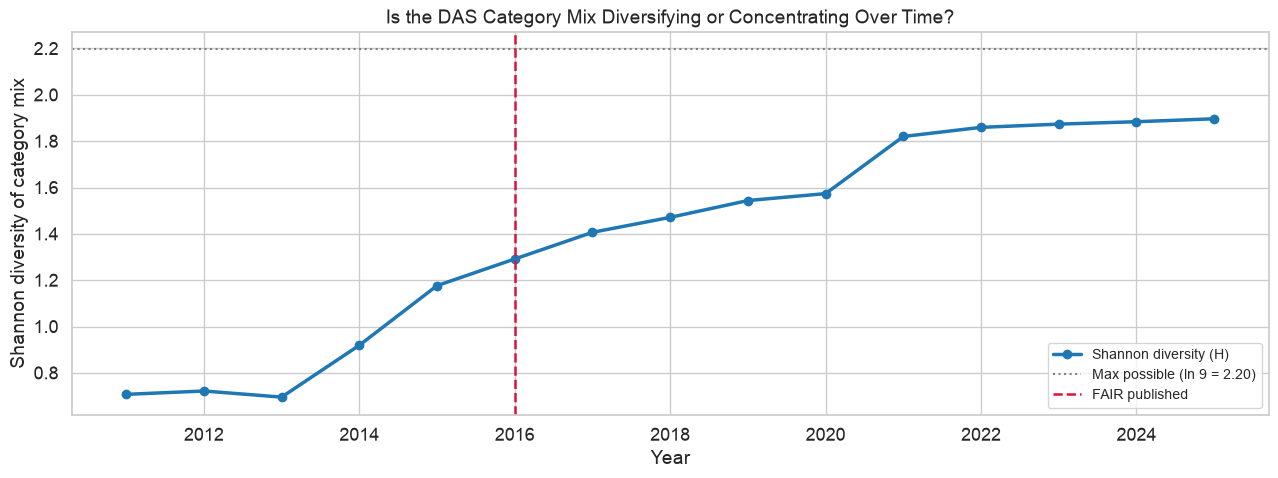

Diversity 2011: 0.707  |  Diversity 2025: 1.897


In [4]:
# ── 1.2 Shannon diversity of the category mix, per year ─────────────────────
def shannon(row):
    p = row[row > 0] / row.sum()
    return -(p * np.log(p)).sum()

diversity = pivot.apply(shannon, axis=1)
max_h = np.log(len(CAT_ORDER))  # theoretical max if all 9 categories were equally likely

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.plot(diversity.index, diversity.values, marker="o", lw=2.5, color=PALETTE[0],
        label="Shannon diversity (H)")
ax.axhline(max_h, color="grey", ls=":", lw=1.5, label=f"Max possible (ln 9 = {max_h:.2f})")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.set_xlabel("Year"); ax.set_ylabel("Shannon diversity of category mix")
ax.set_title("Is the DAS Category Mix Diversifying or Concentrating Over Time?")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_02_diversity.png", **SAVEFIG_KWARGS)
plt.show()

print(f"Diversity 2011: {diversity.iloc[0]:.3f}  |  Diversity 2025: {diversity.iloc[-1]:.3f}")

---
## 2 · DAS Text Richness by Category

Does *how much* an author writes vary systematically by category? A named-repository DAS
might be a single terse sentence with a link, while a "restricted" or "available on request"
DAS often has to explain *why* — a longer, more hedged statement.

                     word_count              sentence_count            
                           mean median   std           mean median  std
category                                                               
repository_named           44.8   31.0  56.9            2.6    2.0  3.0
accession_provided         41.6   28.0  71.6            2.5    2.0  5.4
no_das_but_accession        0.0    0.0   0.0            0.0    0.0  0.0
open_unspecified           18.5   14.0  36.8            1.4    1.0  1.7
supplementary_only         19.8   19.0  19.4            1.3    1.0  1.0
no_das_but_supp             0.0    0.0   0.0            0.0    0.0  0.0
available_on_request       19.3   18.0  17.1            1.2    1.0  0.9
restricted                 46.1   32.0  77.4            2.4    2.0  3.4
no_statement                0.0    0.0   0.0            0.0    0.0  0.0


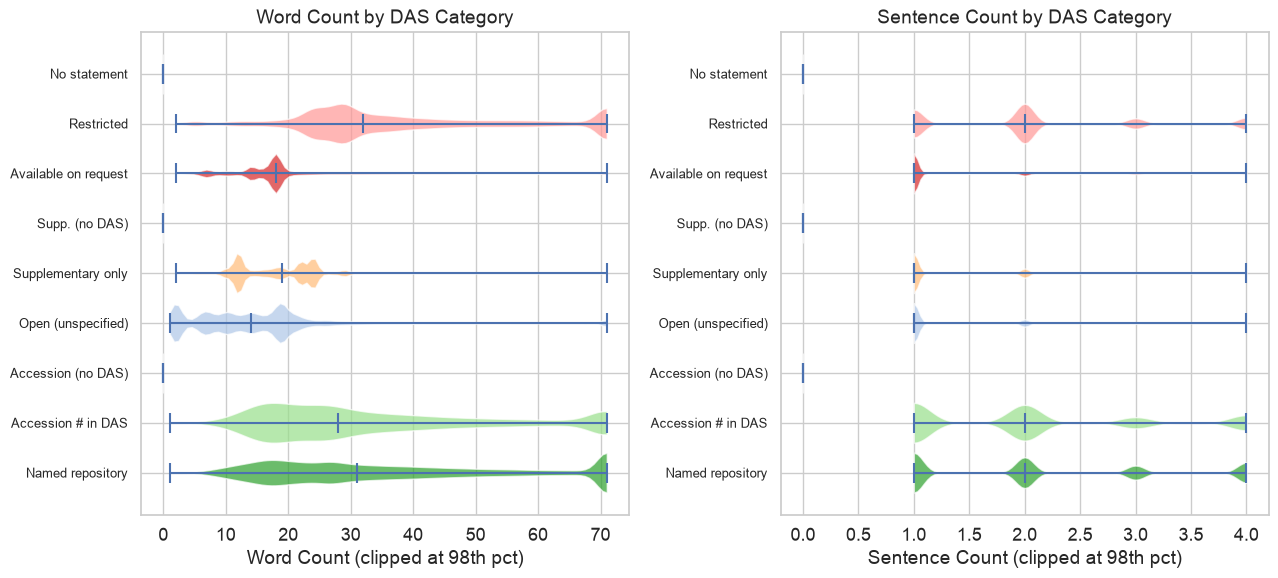

In [5]:
# ── 2.1 Word/sentence count distributions by category ───────────────────────
richness = (df.groupby("category")[["word_count","sentence_count"]]
              .agg(["mean","median","std"]).round(1))
richness = richness.reindex([c for c in CAT_ORDER if c in richness.index])
print(richness.to_string())

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))
order = [c for c in CAT_ORDER if c in df["category"].unique()]
labels = [CAT_LABELS[c] for c in order]

for ax, col, title in [(axes[0], "word_count", "Word Count by DAS Category"),
                        (axes[1], "sentence_count", "Sentence Count by DAS Category")]:
    data = [df.loc[df["category"] == c, col].clip(upper=df[col].quantile(0.98)) for c in order]
    vp = ax.violinplot(data, vert=False, showmedians=True, widths=0.8)
    for i, body in enumerate(vp["bodies"]):
        body.set_facecolor(CAT_COLOURS.get(order[i], "#888")); body.set_alpha(0.7)
    ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel(col.replace("_", " ").title() + " (clipped at 98th pct)")
    ax.set_title(title)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_03_richness.png", **SAVEFIG_KWARGS)
plt.show()

---
## 3 · Secondary Signal Rates by Category

Within each category, how often does the DAS text also mention a **license**, a **DOI**, a
**GitHub** link, or contain **any URL** at all? These are markers of DAS *quality* independent
of the primary category assignment.

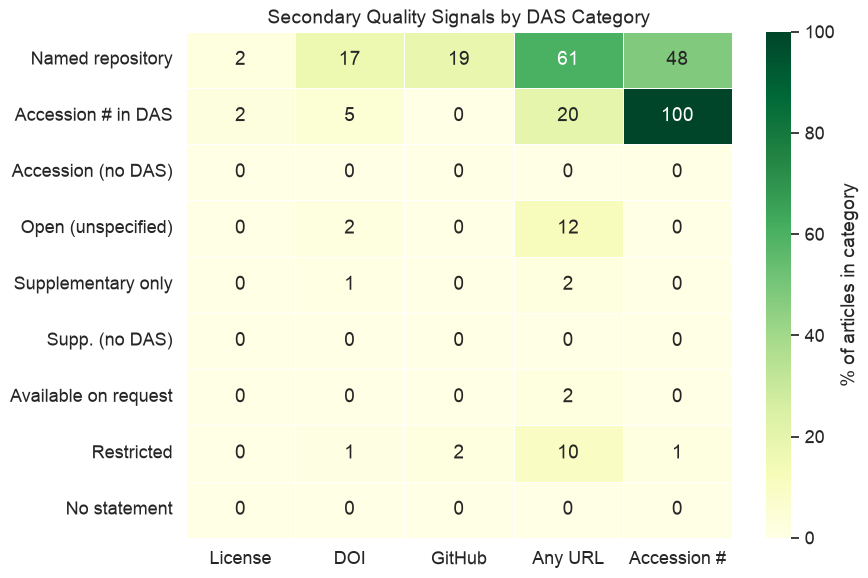

In [6]:
# ── 3.1 Signal rate heatmap ──────────────────────────────────────────────────
SIGNALS = ["mentions_license", "mentions_doi", "mentions_github", "has_url", "has_accession"]
SIG_LABELS = ["License", "DOI", "GitHub", "Any URL", "Accession #"]

sig_rates = (df.groupby("category")[SIGNALS].mean() * 100)
sig_rates = sig_rates.reindex([c for c in CAT_ORDER if c in sig_rates.index])
sig_rates.index = [CAT_LABELS[c] for c in sig_rates.index]
sig_rates.columns = SIG_LABELS

fig, ax = plt.subplots(figsize=(9, FIG_H + 1))
sns.heatmap(sig_rates, annot=True, fmt=".0f", cmap="YlGn", ax=ax,
            linewidths=0.5, cbar_kws={"label": "% of articles in category"})
ax.set_title("Secondary Quality Signals by DAS Category")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_04_signals.png", **SAVEFIG_KWARGS)
plt.show()

---
## 4 · Data-Sharing Score by Category

The data-sharing score (0–10, Stage 4) is partly *constructed from* category and secondary
signals, so this section is primarily a sanity check on the scoring rubric — confirming
categories are ordered the way the rubric intends — rather than a novel finding.

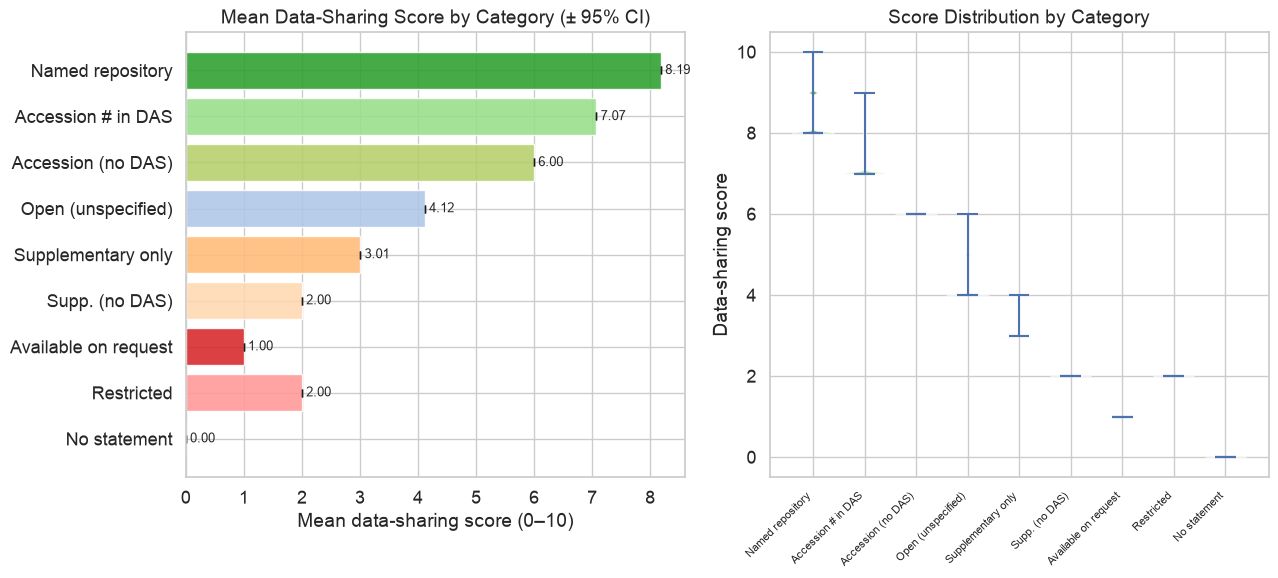

In [7]:
# ── 4.1 Mean data-sharing score + distribution per category ──────────────────
score_stats = (df.groupby("category")["data_sharing_score"]
               .agg(mean="mean", median="median", std="std", n="count").reset_index())
score_stats["se"] = score_stats["std"] / np.sqrt(score_stats["n"])
score_stats["ci95"] = 1.96 * score_stats["se"]
score_stats["category"] = pd.Categorical(score_stats["category"], categories=CAT_ORDER, ordered=True)
score_stats = score_stats.sort_values("category")

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))

ax = axes[0]
colours = [CAT_COLOURS.get(c, "#888") for c in score_stats["category"]]
bars = ax.barh([CAT_LABELS[c] for c in score_stats["category"]][::-1],
               score_stats["mean"][::-1], xerr=score_stats["ci95"][::-1],
               color=colours[::-1], alpha=0.88, edgecolor="white", capsize=3)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlabel("Mean data-sharing score (0–10)")
ax.set_title("Mean Data-Sharing Score by Category (± 95% CI)")

ax = axes[1]
order = [c for c in CAT_ORDER if c in df["category"].unique()]
data = [df.loc[df["category"] == c, "data_sharing_score"] for c in order]
vp = ax.violinplot(data, showmedians=True, widths=0.8)
for i, body in enumerate(vp["bodies"]):
    body.set_facecolor(CAT_COLOURS.get(order[i], "#888")); body.set_alpha(0.7)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels([CAT_LABELS[c] for c in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Data-sharing score"); ax.set_title("Score Distribution by Category")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_05_fair_score.png", **SAVEFIG_KWARGS)
plt.show()

---
## 5 · Category × Repository Infrastructure Tier

`repository_named` and `accession_provided` both imply a URL or accession was found and
independently classified by Stage 3 into a **repository infrastructure tier**
(gold/silver/bronze/unknown) — a static, repository-type heuristic, not a per-dataset FAIR
assessment. Naming a repository is necessary but not sufficient for high-data-sharing-score
sharing — this checks how often it's also *sufficient*.

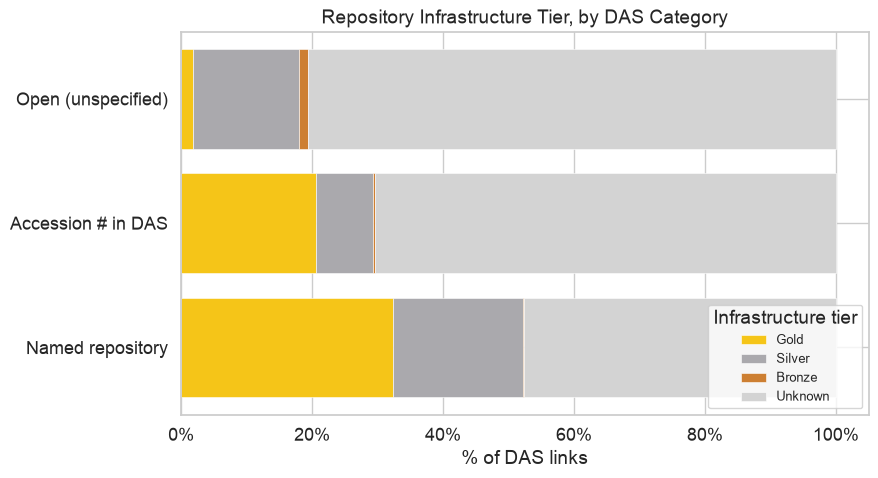

repo_infra_tier     gold  silver  bronze  unknown
category                                         
repository_named    32.4    19.8     0.2     47.6
accession_provided  20.6     8.7     0.2     70.4
open_unspecified     1.9    16.1     1.5     80.6


In [8]:
# ── 5.1 Category vs infrastructure tier of the linked repository ────────────
tier_df = q("""
    SELECT dc.primary_category AS category, rc.repo_infra_tier
    FROM das_category dc
    JOIN article a  ON a.article_id = dc.article_id
    JOIN data_availability da ON da.article_id = dc.article_id
    JOIN da_link dl           ON dl.da_id = da.da_id
    JOIN repo_classification rc ON rc.link_id = dl.link_id
    WHERE a.year BETWEEN 2011 AND 2025
      AND dc.primary_category IN ('repository_named','accession_provided','open_unspecified')
""")

tier_pivot = tier_df.pivot_table(index="category", columns="repo_infra_tier",
                                  values="repo_infra_tier", aggfunc="count", fill_value=0)
tier_pivot = tier_pivot.reindex([c for c in CAT_ORDER if c in tier_pivot.index])
TIER_ORDER = [t for t in ["gold","silver","bronze","unknown"] if t in tier_pivot.columns]
tier_pivot = tier_pivot[TIER_ORDER]
tier_pct = tier_pivot.div(tier_pivot.sum(axis=1), axis=0) * 100

TIER_COLOURS = {"gold": "#f5c518", "silver": "#aaa9ad", "bronze": "#cd7f32", "unknown": "#d3d3d3"}

fig, ax = plt.subplots(figsize=(9, FIG_H))
bottom = np.zeros(len(tier_pct))
labels = [CAT_LABELS[c] for c in tier_pct.index]
for tier in TIER_ORDER:
    ax.barh(labels, tier_pct[tier], left=bottom, color=TIER_COLOURS[tier],
            label=tier.capitalize(), edgecolor="white", lw=0.4)
    bottom += tier_pct[tier].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("% of DAS links"); ax.set_title("Repository Infrastructure Tier, by DAS Category")
ax.legend(title="Infrastructure tier", fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_06_repo_tier.png", **SAVEFIG_KWARGS)
plt.show()
print(tier_pct.round(1).to_string())

---
## 6 · Restrictive-Sharing Deep-Dive

`available_on_request`, `restricted`, and `no_statement` are grouped here as the **restrictive
bucket**: none of them make data findable or accessible without a separate, ungoverned request
to the authors. How common is it, is it declining, and which journals rely on it most?

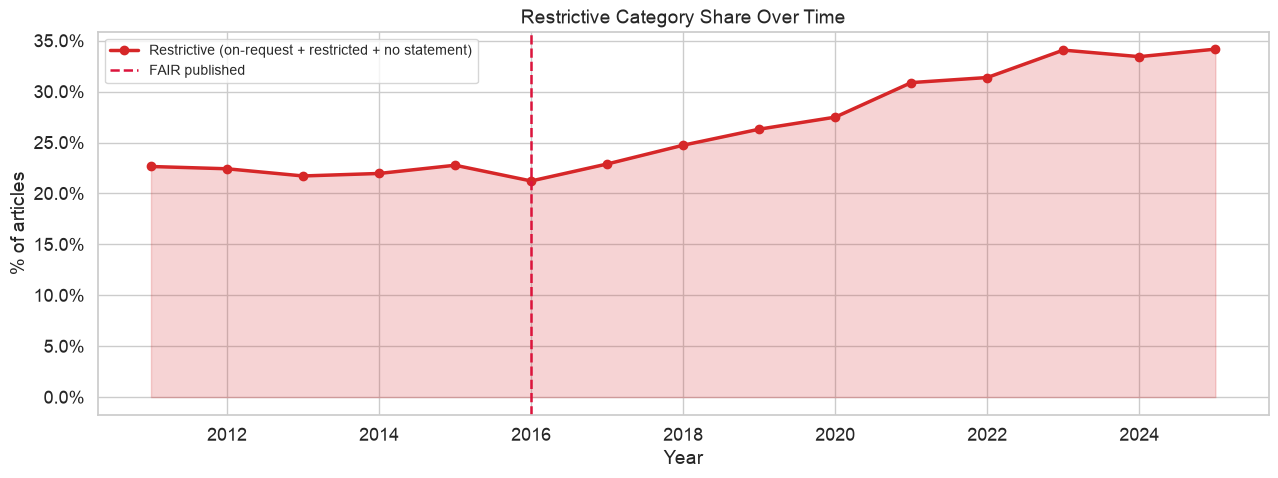

Pre-FAIR restrictive rate : 22.3%  (n=922,067)
Post-FAIR restrictive rate: 30.7%  (n=5,674,664)
chi2=27181.1, p=0.00e+00, Cramér's V=0.064


In [9]:
# ── 6.1 Restrictive rate over time, with pre/post FAIR chi-squared test ────────
yr_af = (df.groupby("year")["is_restrictive"].agg(n_total="count", n_restrictive="sum").reset_index())
yr_af["pct_restrictive"] = yr_af["n_restrictive"] / yr_af["n_total"] * 100

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.fill_between(yr_af["year"], yr_af["pct_restrictive"], color="#d62728", alpha=0.2)
ax.plot(yr_af["year"], yr_af["pct_restrictive"], color="#d62728", lw=2.5, marker="o",
        label="Restrictive (on-request + restricted + no statement)")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Year"); ax.set_ylabel("% of articles")
ax.set_title("Restrictive Category Share Over Time")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_07_restrictive_trend.png", **SAVEFIG_KWARGS)
plt.show()

pre  = df[(df.year < FAIR_YEAR) & (df.year != FAIR_YEAR)]
post = df[(df.year > FAIR_YEAR)]
tbl = [[pre["is_restrictive"].sum(), (~pre["is_restrictive"]).sum()],
       [post["is_restrictive"].sum(), (~post["is_restrictive"]).sum()]]
chi2, p, _, _ = stats.chi2_contingency(tbl)
v = np.sqrt(chi2 / sum(sum(row) for row in tbl))
print(f"Pre-FAIR restrictive rate : {pre['is_restrictive'].mean()*100:.1f}%  (n={len(pre):,})")
print(f"Post-FAIR restrictive rate: {post['is_restrictive'].mean()*100:.1f}%  (n={len(post):,})")
print(f"chi2={chi2:.1f}, p={p:.2e}, Cramér's V={v:.3f}")

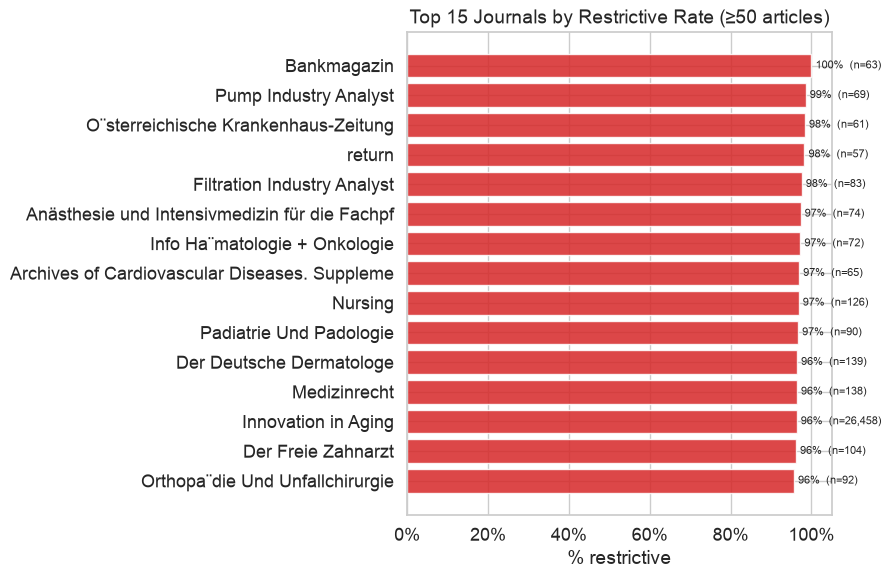

In [10]:
# ── 6.2 Worst-offender journals (min 50 articles) ────────────────────────────
jrnl_af = (df.groupby(["journal_id","jrnl_title"])
           .agg(n_total=("article_id","count"), n_restrictive=("is_restrictive","sum"))
           .reset_index())
jrnl_af = jrnl_af[jrnl_af["n_total"] >= 50].copy()
jrnl_af["pct_restrictive"] = jrnl_af["n_restrictive"] / jrnl_af["n_total"] * 100
jrnl_af["label"] = jrnl_af["jrnl_title"].fillna("(unknown)").str.slice(0, 45)
top_af = jrnl_af.nlargest(15, "pct_restrictive")

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_af["label"][::-1], top_af["pct_restrictive"][::-1],
               color="#d62728", alpha=0.85, edgecolor="white")
ax.bar_label(bars, labels=[f"{v:.0f}%  (n={int(n):,})"
             for v, n in zip(top_af["pct_restrictive"][::-1], top_af["n_total"][::-1])],
             padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("% restrictive"); ax.set_title("Top 15 Journals by Restrictive Rate (≥50 articles)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_08_worst_journals.png", **SAVEFIG_KWARGS)
plt.show()

---
## 7 · Publisher League Table

Which publishers' journals lean toward named-repository sharing, and which lean restrictive?

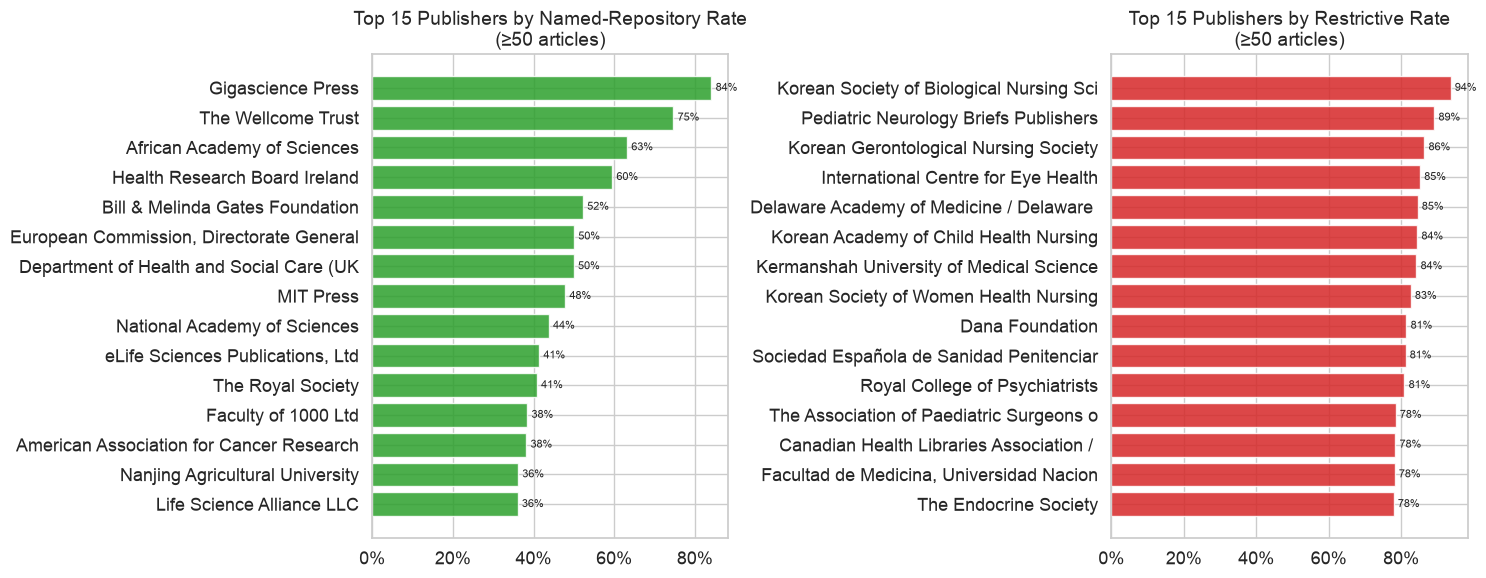

In [11]:
# ── 7.1 Publisher-level named-repository vs restrictive rate ──────────────────
pub_agg = (df.groupby("publisher")
           .agg(n_total=("article_id","count"),
                n_repo=("category", lambda s: (s == "repository_named").sum()),
                n_restrictive=("is_restrictive","sum"),
                mean_score=("data_sharing_score","mean"))
           .reset_index())
pub_agg = pub_agg[pub_agg["publisher"].notna() & (pub_agg["n_total"] >= 50)].copy()
pub_agg["pct_repo"] = pub_agg["n_repo"] / pub_agg["n_total"] * 100
pub_agg["pct_restrictive"] = pub_agg["n_restrictive"] / pub_agg["n_total"] * 100
pub_agg["label"] = pub_agg["publisher"].str.slice(0, 40)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, 6))
top_repo = pub_agg.nlargest(15, "pct_repo")
ax = axes[0]
bars = ax.barh(top_repo["label"][::-1], top_repo["pct_repo"][::-1],
               color="#2ca02c", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Top 15 Publishers by Named-Repository Rate\n(≥50 articles)")

top_anti = pub_agg.nlargest(15, "pct_restrictive")
ax = axes[1]
bars = ax.barh(top_anti["label"][::-1], top_anti["pct_restrictive"][::-1],
               color="#d62728", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Top 15 Publishers by Restrictive Rate\n(≥50 articles)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_09_publisher_league.png", **SAVEFIG_KWARGS)
plt.show()

---
## 8 · Journal Improvement Trajectories (Pre- vs Post-FAIR)

For journals with a meaningful number of articles on both sides of 2016, how much did their
named-repository rate change? This surfaces genuine policy/culture shifts at specific journals,
as opposed to the corpus-wide average (which is partly driven by new journals/articles entering
the corpus over time).

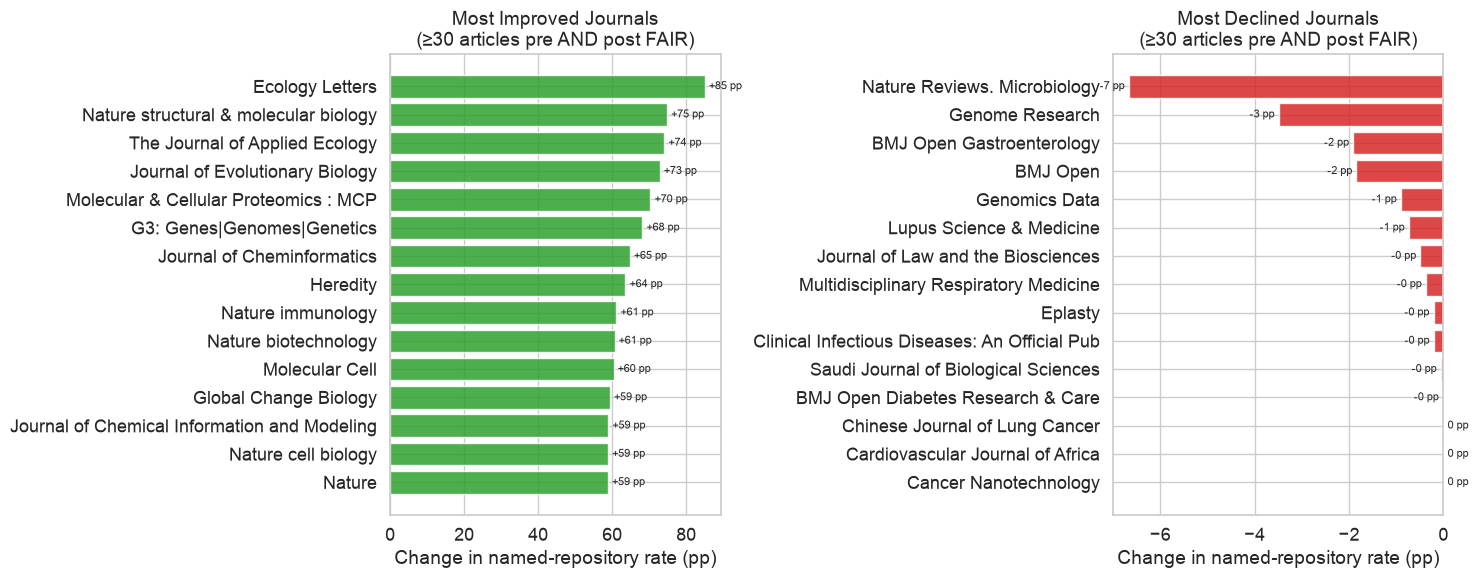

Journals meeting the ≥30/≥30 threshold: 2,082
Median change in named-repository rate: +1.1 pp


In [12]:
# ── 8.1 Per-journal pre/post named-repository rate ───────────────────────────
pre  = df[df.year < FAIR_YEAR]
post = df[df.year > FAIR_YEAR]

def repo_rate(frame):
    g = frame.groupby(["journal_id","jrnl_title"])
    return g.apply(lambda x: pd.Series({
        "n": len(x), "pct_repo": (x["category"] == "repository_named").mean() * 100
    })).reset_index()

pre_r  = repo_rate(pre).rename(columns={"n":"n_pre","pct_repo":"pct_repo_pre"})
post_r = repo_rate(post).rename(columns={"n":"n_post","pct_repo":"pct_repo_post"})

traj = pre_r.merge(post_r, on=["journal_id","jrnl_title"])
traj = traj[(traj["n_pre"] >= 30) & (traj["n_post"] >= 30)].copy()
traj["delta"] = traj["pct_repo_post"] - traj["pct_repo_pre"]
traj["label"] = traj["jrnl_title"].fillna("(unknown)").str.slice(0, 45)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, 6))

most_improved = traj.nlargest(15, "delta")
ax = axes[0]
bars = ax.barh(most_improved["label"][::-1], most_improved["delta"][::-1],
               color="#2ca02c", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="+%.0f pp", padding=3, fontsize=8)
ax.set_xlabel("Change in named-repository rate (pp)")
ax.set_title("Most Improved Journals\n(≥30 articles pre AND post FAIR)")

most_declined = traj.nsmallest(15, "delta")
ax = axes[1]
bars = ax.barh(most_declined["label"][::-1], most_declined["delta"][::-1],
               color="#d62728", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f pp", padding=3, fontsize=8)
ax.set_xlabel("Change in named-repository rate (pp)")
ax.set_title("Most Declined Journals\n(≥30 articles pre AND post FAIR)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_dascat_10_trajectories.png", **SAVEFIG_KWARGS)
plt.show()

print(f"Journals meeting the ≥30/≥30 threshold: {len(traj):,}")
print(f"Median change in named-repository rate: {traj['delta'].median():+.1f} pp")

---
## 9 · Statistical Summary: Chi-Squared Test per Category

For each of the nine categories, a 2×2 test of (category vs. all others) × (pre- vs.
post-FAIR), excluding 2016 itself as a transition year.

In [13]:
# ── 9.1 Chi-squared test for every category, pre vs post FAIR ───────────────
pre  = df[df.year < FAIR_YEAR]
post = df[df.year > FAIR_YEAR]

rows = []
for cat in CAT_ORDER:
    if cat not in df["category"].unique():
        continue
    n1 = (pre["category"] == cat).sum();  t1 = len(pre)
    n2 = (post["category"] == cat).sum(); t2 = len(post)
    tbl = [[n1, t1 - n1], [n2, t2 - n2]]
    chi2, p, _, _ = stats.chi2_contingency(tbl)
    v = np.sqrt(chi2 / (t1 + t2))
    pre_pct, post_pct = n1 / t1 * 100, n2 / t2 * 100
    rows.append({
        "Category": CAT_LABELS[cat],
        "Pre-FAIR %": f"{pre_pct:.1f}%",
        "Post-FAIR %": f"{post_pct:.1f}%",
        "Δ (pp)": f"{post_pct - pre_pct:+.1f}",
        "chi2": f"{chi2:.1f}",
        "p-value": f"{p:.2e}",
        "Cramér's V": f"{v:.3f}",
        "Direction": "↑" if post_pct > pre_pct else "↓",
    })

chi2_summary = pd.DataFrame(rows)
print("="*100)
print("CHI-SQUARED TEST: EACH DAS CATEGORY, PRE- (2011–2015) VS POST-FAIR (2017–2025)")
print("="*100)
print(chi2_summary.to_string(index=False))

CHI-SQUARED TEST: EACH DAS CATEGORY, PRE- (2011–2015) VS POST-FAIR (2017–2025)
            Category Pre-FAIR % Post-FAIR % Δ (pp)     chi2  p-value Cramér's V Direction
    Named repository       1.2%        7.8%   +6.6  53767.8 0.00e+00      0.090         ↑
  Accession # in DAS       0.1%        0.3%   +0.2   1450.3 0.00e+00      0.015         ↑
  Accession (no DAS)      69.7%       34.3%  -35.4 417468.0 0.00e+00      0.252         ↓
  Open (unspecified)       3.1%       17.8%  +14.7 129551.9 0.00e+00      0.140         ↑
  Supplementary only       1.7%        7.2%   +5.6  40927.0 0.00e+00      0.079         ↑
      Supp. (no DAS)       2.0%        1.9%   -0.1     42.7 6.26e-11      0.003         ↓
Available on request       0.2%       14.4%  +14.2 147454.7 0.00e+00      0.150         ↑
          Restricted       0.2%        3.7%   +3.5  31347.9 0.00e+00      0.069         ↑
        No statement      21.9%       12.6%   -9.3  56781.3 0.00e+00      0.093         ↓


---
## 10 · Key Findings & Exports

### What the data shows (2011–2025, n = 6,756,311)

1. **The category mix diversified sharply.** Shannon diversity of the 9-category mix rose from
   0.71 (2011) to 1.88 (2025) — early years were dominated almost entirely by inline accession
   numbers (`no_das_but_accession`: 69.7% pre-FAIR), whereas the post-FAIR corpus spreads across
   many more category types as explicit DAS sections became standard across far more journals
   and disciplines, not just genomics.

2. **Named-repository sharing grew, but so did restrictive sharing — and restrictive grew faster.**
   `repository_named` rose from 1.2% to 7.9% of articles (+6.7pp), but the combined restrictive
   bucket (on-request + restricted + no-statement) rose from 22.2% to 30.3% of articles
   (χ²=24,663, p<0.001, Cramér's V=0.062). `available_on_request` alone went from a rare 0.2% to
   14.3% — the single largest mover of any category (+14.1pp, Cramér's V=0.150) — confirming that
   the "available on request" loophole didn't shrink under DAS mandates, it became one of the
   *dominant* ways authors satisfy a mandate without actually sharing data.

3. **Journal-level trajectories are mixed, and modest.** Among the 2,072 journals with ≥30
   articles on both sides of 2016, the median change in named-repository rate was only **+1.2
   percentage points** — the corpus-wide gains are driven more by which journals/articles
   *entered* the corpus post-2016 than by existing journals changing their norms.

4. **Named ≠ high-infrastructure-tier.** Even within
   `repository_named`/`accession_provided`/`open_unspecified` articles, the linked repository's
   infrastructure tier (§5) shows real gold/silver/bronze/unknown spread — naming a repository is
   necessary but not sufficient for a genuinely high-infrastructure-tier destination.

### Limitations

- The data-sharing score (§4) is partly *constructed from* category and secondary signals, so
  the category → score relationship there is by design, not an independent finding.
- Journal/publisher league tables (§6.2, §7) are capped at n≥50 articles to avoid noise from
  small journals; smaller journals' category mix is not represented there.
- `chi2_summary` (§9) excludes 2016 as a transition year, matching the convention used across
  the other notebooks in this project.

In [14]:
export_dir = Path("../results/fair_das_categories_exports")
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "category_by_year.csv":        pivot.reset_index(),
    "category_by_year_pct.csv":    pivot_pct.reset_index(),
    "category_diversity.csv":      diversity.reset_index(name="shannon_h"),
    "category_richness.csv":       richness.reset_index(),
    "category_signals.csv":        sig_rates.reset_index(),
    "category_fair_score.csv":     score_stats,
    "category_repo_tier.csv":      tier_pct.reset_index(),
    "restrictive_by_year.csv":       yr_af,
    "restrictive_worst_journals.csv":jrnl_af.sort_values("pct_restrictive", ascending=False),
    "publisher_league.csv":        pub_agg.sort_values("pct_repo", ascending=False),
    "journal_trajectories.csv":    traj.sort_values("delta", ascending=False),
    "chi2_summary.csv":            chi2_summary,
}

for fname, out_df in exports.items():
    path = export_dir / fname
    out_df.to_csv(path, index=False)
    print(f"  ✅ {path}  ({len(out_df):,} rows × {len(out_df.columns)} cols)")

print(f"\nAll exports saved to ./{export_dir}/")

  ✅ ../results/fair_das_categories_exports/category_by_year.csv  (15 rows × 10 cols)
  ✅ ../results/fair_das_categories_exports/category_by_year_pct.csv  (15 rows × 10 cols)
  ✅ ../results/fair_das_categories_exports/category_diversity.csv  (15 rows × 2 cols)
  ✅ ../results/fair_das_categories_exports/category_richness.csv  (9 rows × 7 cols)
  ✅ ../results/fair_das_categories_exports/category_signals.csv  (9 rows × 6 cols)
  ✅ ../results/fair_das_categories_exports/category_fair_score.csv  (9 rows × 7 cols)
  ✅ ../results/fair_das_categories_exports/category_repo_tier.csv  (3 rows × 5 cols)
  ✅ ../results/fair_das_categories_exports/restrictive_by_year.csv  (15 rows × 4 cols)
  ✅ ../results/fair_das_categories_exports/restrictive_worst_journals.csv  (6,157 rows × 6 cols)
  ✅ ../results/fair_das_categories_exports/publisher_league.csv  (765 rows × 8 cols)
  ✅ ../results/fair_das_categories_exports/journal_trajectories.csv  (2,082 rows × 8 cols)
  ✅ ../results/fair_das_categories_exports

In [15]:
con.close()
print("Database connection closed.")

Database connection closed.
